## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Phishing_clean.parquet to Phishing_clean.parquet
Saving all_tokens.pickle to all_tokens.pickle


In [4]:
# Your Phase 1 solution to the problem goes here.
#Question 1 - got rid of the data/
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [6]:
import matplotlib.pyplot as plt

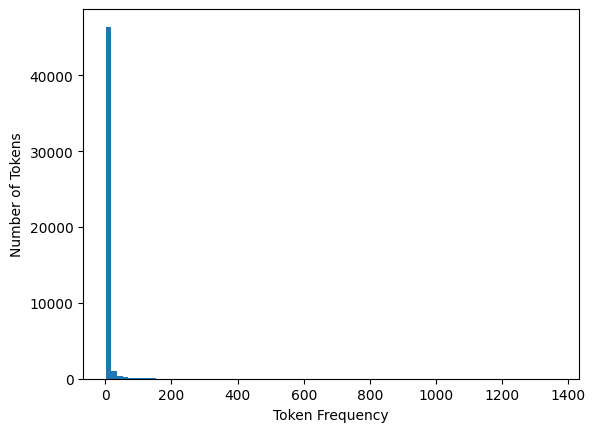

In [9]:
#I notice that the plot is heavily skewed. Many of the tokens are appearing very infrequently while only a small number of tokens appear more.
plt.hist(list(token_count.values()), bins=80)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.show()

In [11]:
#Q2.1 - importing and loading dataset, then using df.drop to remove 'Email Type' from X so only the word features remain as our predictors and assigning 'Email Type' to y as the outcome we want to predict, and split both into 80% training and 20% testing data.
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_parquet('Phishing_clean.parquet')
X = df.drop(columns=['Email Type'])
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=88)


In [12]:
#2.2 - creating a linear regression model - using fit.() to calculate coefficients from training data and predict.() tp generate predicted values for bothh datasets and using use r2_score() to compare predictions with actual values
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
model = LinearRegression()
model.fit(X_train, y_train)
y_train1 = model.predict(X_train)
y_test1 = model.predict(X_test)


r2_score(y_train, y_train1), r2_score(y_test, y_test1)

#r squared on training set is 0.77 and 0.66 for the test set.


(0.7673743160696023, 0.6647625201943957)

In [14]:
#2.3 - using model.coef_ to extract the coefficients and pd.Series()to match them with their words. .abs() to calculate absolute values because we want the largest coefficient and sort_values() to rank them.

coefficients = pd.Series(model.coef_, index=X.columns)

words = coefficients.abs().sort_values(ascending=False).head(5)

coefficients.loc[words.index]

#The five tokens with the largest absolute coefficients are background-image:, localized, aging, rhythm, and rcs.

,0
background-image:,-0.820291
localized,0.777744
aging,0.721564
rhythm,0.675414
rcs,0.644032


In [16]:
# Question 3
from sklearn.decomposition import PCA

In [18]:
#Using PCA(n_components=2) to create a PCA model with two components and .fit_transform() to reduce the token matrix X to two principal components.

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

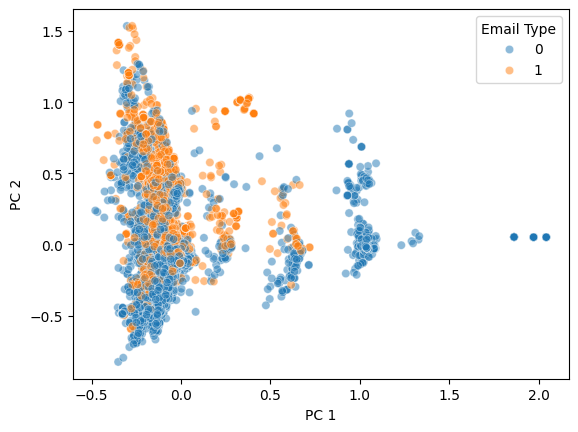

In [20]:
# creating the hue and sctatter plots
import seaborn as sns
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, alpha=0.5)

plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()

#There's a lot of overlap between legit and scam emails indicating that the two principal componenets are not enough to completely distinguish between scam and legit emails and this is especially clear in the cluster to the left. There are several smaller clusters toward the right with higher values of PC1 that consist almost entirely of legitimate emails. This suggests that the first two principal components capture some differences between the email types.

In [ ]:
#Question 4


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]